Chris McCarthy
DSC 540
Term Project: Milestone 2
Winter 2026

Performing 5 Data Transformations

Electric_Vehicle_Population csv (flat file)

Load File

In [1]:
import pandas as pd

df = pd.read_csv("../data/Electric_Vehicle_Population_Data.csv")
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,5YJ3E1EB9J,Kitsap,Bainbridge Island,WA,98110.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,23.0,476462444,POINT (-122.521 47.62732),PUGET SOUND ENERGY INC,5.303509e+10
1,JN1AZ0CP2B,Kitsap,Port Orchard,WA,98367.0,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,26.0,279030461,POINT (-122.70348 47.52028),PUGET SOUND ENERGY INC,5.303509e+10
2,JN1AZ0CP8B,King,Bothell,WA,98011.0,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,1.0,232370001,POINT (-122.20563 47.76144),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
3,1G1FY6S06L,Yakima,Selah,WA,98942.0,2020,CHEVROLET,BOLT EV,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,259.0,15.0,264646266,POINT (-120.53145 46.65405),PACIFICORP,5.307700e+10
4,KNDCM3LD3L,King,Seattle,WA,98133.0,2020,KIA,NIRO,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,26.0,32.0,154002691,POINT (-122.33364 47.73709),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10


Data Transformation 1 - Standardize Column Names

In [2]:
df.columns = (
    df.columns
      .str.lower()
      .str.replace(" ", "_")
      .str.replace("(", "", regex=False)
      .str.replace(")", "", regex=False)
)

df.columns
df.head()

,vin_1-10,county,city,state,postal_code,model_year,make,model,electric_vehicle_type,clean_alternative_fuel_vehicle_cafv_eligibility,electric_range,legislative_district,dol_vehicle_id,vehicle_location,electric_utility,2020_census_tract
0,5YJ3E1EB9J,Kitsap,Bainbridge Island,WA,98110.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,23.0,476462444,POINT (-122.521 47.62732),PUGET SOUND ENERGY INC,5.303509e+10
1,JN1AZ0CP2B,Kitsap,Port Orchard,WA,98367.0,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,26.0,279030461,POINT (-122.70348 47.52028),PUGET SOUND ENERGY INC,5.303509e+10
2,JN1AZ0CP8B,King,Bothell,WA,98011.0,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,1.0,232370001,POINT (-122.20563 47.76144),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
3,1G1FY6S06L,Yakima,Selah,WA,98942.0,2020,CHEVROLET,BOLT EV,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,259.0,15.0,264646266,POINT (-120.53145 46.65405),PACIFICORP,5.307700e+10
4,KNDCM3LD3L,King,Seattle,WA,98133.0,2020,KIA,NIRO,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,26.0,32.0,154002691,POINT (-122.33364 47.73709),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10


I went ahead and standardized the casing of each column. Everything is lowercase. I also removed spaces and special characters and replaced them with underscores. This makes the data more consistent to work with in a database / coding context.

Data Transformation 2 - Missing Values

In [3]:
df.isna().sum().sort_values(ascending=False)
#checking for missing values

legislative_district                               659
vehicle_location                                    88
county                                              10
city                                                10
postal_code                                         10
electric_utility                                    10
2020_census_tract                                   10
electric_range                                       7
vin_1-10                                             0
state                                                0
model_year                                           0
make                                                 0
model                                                0
electric_vehicle_type                                0
clean_alternative_fuel_vehicle_cafv_eligibility      0
dol_vehicle_id                                       0
dtype: int64

In [4]:
#counting rows before / after dropping
#I've decided county and city are most important for my analysis
#I'm dropping any rows that lack those

rows_before = df.shape[0]

df = df.dropna(subset=["county", "city"])

rows_after = df.shape[0]

print(f"Rows before drop: {rows_before}")
print(f"Rows after drop:  {rows_after}")
print(f"Rows removed:    {rows_before - rows_after}")

Rows before drop: 271113
Rows after drop:  271103
Rows removed:    10


Data Transformation 3 - Validating Categorical Values

In [5]:
df[["county", "city"]].nunique()

county    246
city      870
dtype: int64

WA only has 39 counties and 281 cities so this shows a lot of geodiversity of EV registration in the state.

In [6]:
df["county"].value_counts().head(10)

county
King         133815
Snohomish     33766
Pierce        22238
Clark         16694
Thurston       9911
Kitsap         9116
Spokane        7652
Whatcom        6664
Benton         3827
Skagit         3194
Name: count, dtype: int64

A snapshot of top 10 counties shows no duplicates. King should also be the largest as the metropolitan area of Seattle, so this checks out.

Ultimately, categorical cleaning was unnecessary because the state of the dataset was already pretty clean. Instead, I opted for validation and also generating some insights based on the categorical cleanliness.

Data Transformation 4 - Checking Data Types (and converting if necessary)

In [7]:
df.dtypes

vin_1-10                                            object
county                                              object
city                                                object
state                                               object
postal_code                                        float64
model_year                                           int64
make                                                object
model                                               object
electric_vehicle_type                               object
clean_alternative_fuel_vehicle_cafv_eligibility     object
electric_range                                     float64
legislative_district                               float64
dol_vehicle_id                                       int64
vehicle_location                                    object
electric_utility                                    object
2020_census_tract                                  float64
dtype: object

After examining the data types, they are all correctly paired up. One change I will make is to postal_code. I will convert it from a float to a string because it protects against leading zeros and math isn't performed on zip codes.

In [8]:
df["postal_code"] = (
    df["postal_code"]
        .astype("Int64")   # handle NaN 
        .astype("string")  # convert to string
)

In [10]:
#checking df type now

df.dtypes

vin_1-10                                                   object
county                                                     object
city                                                       object
state                                                      object
postal_code                                        string[python]
model_year                                                  int64
make                                                       object
model                                                      object
electric_vehicle_type                                      object
clean_alternative_fuel_vehicle_cafv_eligibility            object
electric_range                                            float64
legislative_district                                      float64
dol_vehicle_id                                              int64
vehicle_location                                           object
electric_utility                                           object
2020_censu

Successful conversion to string.

Overall, the different numeric, categorical and identifier fields were accurate represented by their data type. The dataset has shown itself to be clean and consistent. Since this is the case, I didn't make any unnecessary transformations. However, I do think of the options available to me, converting postal_code from float to string was a prudent choice. There will be no issues with postal_code since it serves as an identifier.

Data Transformation 5 - Identifying Outliers

I want to examine electric_range and determine if there are outliers in the different models of EVs

In [11]:
df["electric_range"].describe()
#looking at statistical tests

count    271096.000000
mean         39.885428
std          78.764248
min           0.000000
25%           0.000000
50%           0.000000
75%          33.000000
max         337.000000
Name: electric_range, dtype: float64

In [12]:
#running IQR

Q1 = df["electric_range"].quantile(0.25)
Q3 = df["electric_range"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

lower_bound, upper_bound

(-49.5, 82.5)

In [14]:
# for now, I just want to flag outliers. creating a new column for them

df["electric_range_outlier"] = (
    (df["electric_range"] < lower_bound) |
    (df["electric_range"] > upper_bound)
)

In [15]:
# showing the column

df.loc[df["electric_range_outlier"], "electric_range"].head(10)

0     215.0
3     259.0
7     215.0
8     249.0
11    220.0
13    150.0
14    200.0
16    238.0
17    291.0
19    215.0
Name: electric_range, dtype: float64

In [16]:
# total count

df["electric_range_outlier"].value_counts()

electric_range_outlier
False    228613
True      42490
Name: count, dtype: int64

<Axes: >

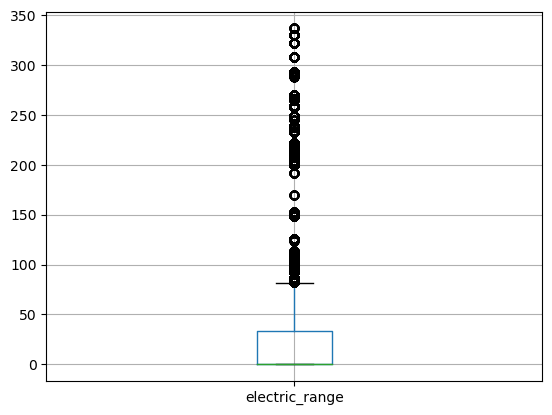

In [17]:
# boxplot for visual

df.boxplot(column="electric_range")

After running statistical tests through describe, IQR, counts, and a boxplot, let's analyze the results. From the data provided so far, the mean is 39.88 miles for electric_range. This indicates the presence of many plug-in hybrids with minimal full electric range. The outliers listed show battery electric vehicles (BEVs) that perform at the top end of 150-300 miles. The max is 337 miles which lines up with information on modern EVs. Given the stats and the clustering on the boxplot, electric_range is heavily skewed to the right. This is likely due to a large number of low range hybrid EVs. This is insightful because now I have a couple things to consider when continuing my analysis and hypothesizing. A good place to start would be differentiating between plug-in hybrids and full battery EVs and getting a count.

Outro Paragraph on Ethical Implications

What changes were made to the data?

I standardized column names, dropped rows missing values for city/county, validated categorical values, checked data types, converted postal_code from float to string, identifier outliers, and flagged them in their own column.

Are there any legal or regulatory guidelines for your data or project topic?

I aim to keep my data as consistent with the open source csv as possible. I am also educating myself on EV taxes, incentives, policies and more.

What risks could be created based on the transformations done?

Honestly, the dataset is originally pretty clean. My transformations are low-risk and err on the side of validation and generating insights.

Did you make any assumptions in cleaning/transforming the data?

The primary assumption I made was the importance of city/county as a value. The biggest transformation I made to the dataset was the dropping of rows that did not contain those values.

How was your data sourced/verified for credibility?

It is public access from data.gov as a record of EV registrations in WA state

Was your data acquired in an ethical way?

I believe the DoL is ethical in its practices

How would you mitigate any of the ethical implications you have identified?

I would call them out and make known any ethical implications. However, I think I will have more ethical considerations when further analyzing the data and EV policies. I believe most of my ethical concern will be in relation to affordability, availability and fairness, especially in consideration of income and environmental impact.

In [18]:
# human readable dataset with transformations

df.head(20)

,vin_1-10,county,city,state,postal_code,model_year,make,model,electric_vehicle_type,clean_alternative_fuel_vehicle_cafv_eligibility,electric_range,legislative_district,dol_vehicle_id,vehicle_location,electric_utility,2020_census_tract,electric_range_outlier
0,5YJ3E1EB9J,Kitsap,Bainbridge Island,WA,98110,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,23.0,476462444,POINT (-122.521 47.62732),PUGET SOUND ENERGY INC,5.303509e+10,True
1,JN1AZ0CP2B,Kitsap,Port Orchard,WA,98367,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,26.0,279030461,POINT (-122.70348 47.52028),PUGET SOUND ENERGY INC,5.303509e+10,False
2,JN1AZ0CP8B,King,Bothell,WA,98011,2011,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,73.0,1.0,232370001,POINT (-122.20563 47.76144),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10,False
3,1G1FY6S06L,Yakima,Selah,WA,98942,2020,CHEVROLET,BOLT EV,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,259.0,15.0,264646266,POINT (-120.53145 46.65405),PACIFICORP,5.307700e+10,True
4,KNDCM3LD3L,King,Seattle,WA,98133,2020,KIA,NIRO,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,26.0,32.0,154002691,POINT (-122.33364 47.73709),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10,False
5,KNDCS3LF9P,Thurston,Olympia,WA,98502,2023,KIA,NIRO,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,33.0,22.0,249788311,POINT (-122.92333 47.03779),PUGET SOUND ENERGY INC,5.306701e+10,False
6,WAUUPBFF9G,King,Seattle,WA,98103,2016,AUDI,A3,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,16.0,43.0,198988891,POINT (-122.35436 47.67596),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10,False
7,5YJ3E1EB9J,Thurston,Tumwater,WA,98512,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215.0,22.0,115875693,POINT (-123.04078 46.94792),PUGET SOUND ENERGY INC,5.306701e+10,True
8,5YJSA1E20J,Kitsap,Bremerton,WA,98337,2018,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,249.0,26.0,261482455,POINT (-122.62749 47.565),PUGET SOUND ENERGY INC,5.303508e+10,True
9,1G1RD6S55H,Snohomish,Lynnwood,WA,98087,2017,CHEVROLET,VOLT,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,53.0,21.0,117693012,POINT (-122.27981 47.85727),PUGET SOUND ENERGY INC,5.306104e+10,False
